# CODE 6.1: Prepare the Demo

> **Goal:** prepare the two small files the dashboard needs, so the app can replay the test months without the big data files and without running a model.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/signals_used.json` (4.1), `models/isolation_forest.joblib` (4.1), `results/alarm_rules.json` (5.1) and `results/window_scores.parquet` (5.2).
> - **Output:** `app/data/readings.parquet` and `app/data/forest_parts.parquet`. At the end you should see **ALL CHECKS PASSED**.
>
> Nothing here changes a rule, a limit or a result. This notebook only cuts out what the app shows.

### What the App Needs

> The dashboard (`app/app.py`) has three pages: **Replay**, **Results** and **How it works**. It replays saved results: no model runs inside it. Most of what it shows is already saved in `results/`. Only two things are missing:
>
> | What the app shows | Where it comes from |
> | --- | --- |
> | the leaks and their zones | `results/leaks.csv` (1.2) |
> | the limits | `results/alarm_rules.json` (5.1) |
> | the score, the error and the alarms of every window, and the LSTM error of every signal | `results/window_scores.parquet` (5.2) |
> | the result cards and the table of first alarms | `results/test_results.csv` (5.2) |
> | the alarm events and what they look like | `results/alarm_events.csv` (5.3) |
> | what other limits would have given | `results/tradeoff.csv` (5.4) |
> | **what the compressor did, minute by minute** | **new:** `app/data/readings.parquet` |
> | **why the forest scored each window (SHAP per signal)** | **new:** `app/data/forest_parts.parquet` |
>
> Why new files? The readings are in `grid.npz`, a large file that notebook 3.1 makes again and that is not in the repo. The SHAP values need the forest and the `shap` library. The app should stay small and light, also online. So this notebook cuts out only what the app needs, like cutting a long CCTV recording down to the clips you want to show.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `hashlib`: folders and file paths, the rules file, and fingerprints of files.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: a preview of what the Replay page will draw; `matplotlib.dates` writes the times on its axis.
> - `joblib`: loads the Isolation Forest of notebook 4.1.
> - `shap`: splits the score of the forest into one part per summary number (SHAP values), as in notebook 5.3.
> - `tqdm`: shows a progress bar while SHAP splits the scores.
>
> Importing `shap` may print a `TqdmWarning` that `IProgress` was not found. It only means that progress bars are shown as plain text, and it can be ignored.

In [1]:
import os
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import joblib
import shap
from tqdm import tqdm

c:\Users\Kelvin Jonathan\Downloads\predictive-maintenance-metropt\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Variables

#### Folder Paths

> The inputs from notebooks 3.1 to 5.2, and the folder of the app, where the two new files go.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
RULES_FILE = os.path.join(RESULTS_DIR, "alarm_rules.json")
SCORES_FILE = os.path.join(RESULTS_DIR, "window_scores.parquet")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
FOREST_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
APP_DATA_DIR = os.path.join(ROOT_DIR, "app", "data")
READINGS_FILE = os.path.join(APP_DATA_DIR, "readings.parquet")
PARTS_FILE = os.path.join(APP_DATA_DIR, "forest_parts.parquet")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `READING_SIGNALS`: the three signals the Replay page draws: `Reservoirs` (the tank pressure), `DV_eletric` (1 = the pump is pumping) and `DV_pressure` (the air dryer).
> - `MINUTE`: the readings are averaged per minute. For the pressures this is a mean in bar; for `DV_eletric` it is the share of the minute the pump was pumping (0 to 1).
> - `CYCLE_FEATURES`, `SHAP_CHUNK`: as in notebook 5.3: the three summary numbers about the pump cycles, gathered as their own group, and how many windows SHAP splits at a time.
> - `CHECK_MINUTES`, `SEED`: how many random minutes a check rebuilds slowly, tick by tick, and the seed that picks them.
> - `PREVIEW_FROM`, `PREVIEW_UNTIL`: the hours of the preview chart: the night before leak 4 and the leak itself (notebook 5.3).

In [3]:
READING_SIGNALS = ["Reservoirs", "DV_eletric", "DV_pressure"]
MINUTE = "1min"
CYCLE_FEATURES = ["pump_starts", "drop_bar_per_min", "rise_bar_per_min"]
SHAP_CHUNK = 2048
CHECK_MINUTES = 30
SEED = 42
PREVIEW_FROM = "2020-07-14 21:00"
PREVIEW_UNTIL = "2020-07-15 20:00"

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Fingerprints (from 5.1)

> `file_fingerprint()` and `rules_fingerprint()` are copied unchanged from notebook 5.1: a code of 64 characters computed from every byte of a file, or from the rules.

In [5]:
def file_fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

In [6]:
def rules_fingerprint(rules):
    text = json.dumps({key: value for key, value in rules.items() if key != "fingerprint"}, sort_keys=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

### Back to Real Units

> Notebook 3.1 scaled the analog signals for the LSTM: minus their February mean, divided by their February spread (std). `real_units()` undoes this for one signal, so the app shows bar again. On/off signals were never scaled, so they come back unchanged.

In [7]:
def real_units(values, signal, scaled_columns, scale_mean, scale_std):
    if signal not in scaled_columns:
        return values
    position = scaled_columns.index(signal)
    return values * scale_std[position] + scale_mean[position]

### SHAP Helpers (from 5.3)

> Copied unchanged from notebook 5.3:
>
> - `average_path_length()`: the yardstick of the Isolation Forest paper that turns a path length into a score: score = 2 ^ (− path length / c).
> - `forest_shap()`: asks SHAP for the split of every window, chunk by chunk, with a progress bar.
> - `parts_per_signal()`: adds up the parts that belong to the same signal.

In [8]:
def average_path_length(n):
    return 2 * (np.log(n - 1) + np.euler_gamma) - 2 * (n - 1) / n

In [9]:
def forest_shap(explainer, features, chunk_size, label):
    parts = [explainer.shap_values(features.iloc[start:start + chunk_size]) for start in tqdm(range(0, len(features), chunk_size), desc=label)]
    return np.vstack(parts)

In [10]:
def parts_per_signal(parts, signal_of, signal_order):
    return parts.T.groupby(parts.columns.map(signal_of)).sum().T.reindex(columns=signal_order)

## Load Everything

### Read the Files

> The grid of notebook 3.1, the windows, the saved scores of notebook 5.2 and the rules of notebook 5.1. Only the test months (April to August) are used: the Replay page shows them.

In [11]:
with np.load(GRID_FILE) as saved:
    grid_values, has_reading, tick_seconds = saved["values"], saved["has_reading"], saved["tick_seconds"]
    grid_signals, scaled_columns = saved["signals"].tolist(), saved["scaled_columns"].tolist()
    scale_mean, scale_std = saved["scale_mean"], saved["scale_std"]
df_windows = pd.read_parquet(WINDOWS_FILE)
df_scores = pd.read_parquet(SCORES_FILE)
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_info = json.load(f)
with open(RULES_FILE, encoding="utf-8") as f:
    rules = json.load(f)

FEATURE_COLUMNS = signals_info["isolation_forest_features"]
SIGNALS = signals_info["signals"]
df_test_windows = df_windows[df_windows["split"] == "test"].reset_index(drop=True)
df_test = df_scores[df_scores["split"] == "test"].reset_index(drop=True)

print(f"grid.npz: {os.path.getsize(GRID_FILE) / 1e6:,.0f} MB, {len(grid_values):,} ticks of 10 seconds")
print(f"Test windows: {len(df_test):,}, from {df_test['end'].min()} to {df_test['end'].max()}")
check("the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)", rules_fingerprint(rules=rules) == rules["fingerprint"])
check("the test windows of window_scores.parquet are the test windows of notebook 3.1, in the same order",
      np.array_equal(df_test_windows["end"].to_numpy(), df_test["end"].to_numpy()))

grid.npz: 127 MB, 1,841,760 ticks of 10 seconds
Test windows: 33,507, from 2020-04-01 00:00:00 to 2020-09-01 03:55:00
PASS  the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)
PASS  the test windows of window_scores.parquet are the test windows of notebook 3.1, in the same order


### Load the Forest

> The forest of notebook 4.1, and a check that it is exactly the file the limits were set for. It is a joblib file: only load joblib files you made yourself, because loading one can run code (notebook 4.1).

In [12]:
forest = joblib.load(FOREST_FILE)
fingerprint = file_fingerprint(path=FOREST_FILE)
print(f"isolation_forest.joblib: {fingerprint[:16]}... | saved by notebook 5.1: {rules['model_files']['isolation_forest.joblib'][:16]}...")
check("the forest file is exactly the one the limits were set for (its fingerprint matches)", fingerprint == rules["model_files"]["isolation_forest.joblib"])

isolation_forest.joblib: 5097501b4dda5e40... | saved by notebook 5.1: 5097501b4dda5e40...
PASS  the forest file is exactly the one the limits were set for (its fingerprint matches)


## What the Compressor Did, Minute by Minute

### Average Every Minute

> We take every tick that has a reading (notebook 3.1 marks the empty ticks), from one hour before the first test window on: the first windows of April reach back into the last hour of March. `Reservoirs` and `DV_pressure` are turned back into bar, and every minute is averaged. Minutes without any reading are left out: there the app draws a gap, like the gaps of notebook 1.1. The table shows the smallest, the middle and the largest value of every column.

In [13]:
readings_from = df_test["end"].min() - pd.Timedelta(minutes=60)
in_replay = (tick_seconds > readings_from.value // 10**9) & has_reading
df_readings = pd.DataFrame({"minute": pd.to_datetime(tick_seconds[in_replay], unit="s").floor(MINUTE)})
for signal in READING_SIGNALS:
    df_readings[signal] = real_units(values=grid_values[in_replay, grid_signals.index(signal)].astype("float64"), signal=signal,
                                     scaled_columns=scaled_columns, scale_mean=scale_mean, scale_std=scale_std)
df_readings = df_readings.groupby("minute", as_index=False).mean()

display(df_readings[READING_SIGNALS].describe().loc[["min", "50%", "max"]].rename(index={"50%": "middle"}).round(2))
print(f"Ticks with a reading: {in_replay.sum():,} | minutes with a reading: {len(df_readings):,}, "
      f"from {df_readings['minute'].min()} to {df_readings['minute'].max()}")

,Reservoirs,DV_eletric,DV_pressure
min,0.95,0.0,-0.03
middle,8.94,0.0,-0.02
max,10.24,1.0,4.11


Ticks with a reading: 1,074,118 | minutes with a reading: 179,230, from 2020-03-31 23:00:00 to 2020-09-01 03:59:00


> **What we see:** the tank pressure stays in the range of a working compressor most of the time, with a few dips (the tanks below 7 bar of notebook 5.3). The middle value of `DV_eletric` is 0: in most minutes the pump rests. `DV_pressure` is near 0 most of the time, as notebook 1.1 described.

### Two Checks on the Minutes

> 1. `CHECK_MINUTES` random minutes are rebuilt slowly: we take their ticks straight from the grid, one minute at a time, and average them again. They must give the same values.
> 2. A window exists only when its whole hour has readings (notebook 3.1). So every test window must find all 60 minutes of its hour in the file, and the Replay page never shows a score without the readings behind it.

In [14]:
picked = df_readings.sample(n=CHECK_MINUTES, random_state=SEED)
rebuilt = []
for row in picked.itertuples():
    first = row.minute.value // 10**9
    inside = in_replay & (tick_seconds >= first) & (tick_seconds < first + 60)
    rebuilt.append([real_units(values=grid_values[inside, grid_signals.index(signal)].astype("float64"), signal=signal, scaled_columns=scaled_columns,
                               scale_mean=scale_mean, scale_std=scale_std).mean() for signal in READING_SIGNALS])
minutes = df_readings["minute"].to_numpy()
window_ends = df_test["end"].to_numpy()
inside_hour = np.searchsorted(minutes, window_ends, side="right") - np.searchsorted(minutes, window_ends - np.timedelta64(60, "m"), side="right")

print(f"Largest difference in the rebuilt minutes: {np.abs(np.array(rebuilt) - picked[READING_SIGNALS].to_numpy()).max():.1e}")
print(f"Minutes with a reading inside the hour of a test window: from {inside_hour.min()} to {inside_hour.max()}")
check(f"{CHECK_MINUTES} random minutes, rebuilt slowly tick by tick, give the same values", np.allclose(np.array(rebuilt), picked[READING_SIGNALS].to_numpy(), rtol=0, atol=1e-9))
check("every test window finds all 60 minutes of its hour in the file", (inside_hour == 60).all())

Largest difference in the rebuilt minutes: 1.8e-15
Minutes with a reading inside the hour of a test window: from 60 to 60
PASS  30 random minutes, rebuilt slowly tick by tick, give the same values
PASS  every test window finds all 60 minutes of its hour in the file


### A Preview: the Night Before Leak 4

> What the Replay page will draw for these hours, with the same three signals. The gap is time without readings.

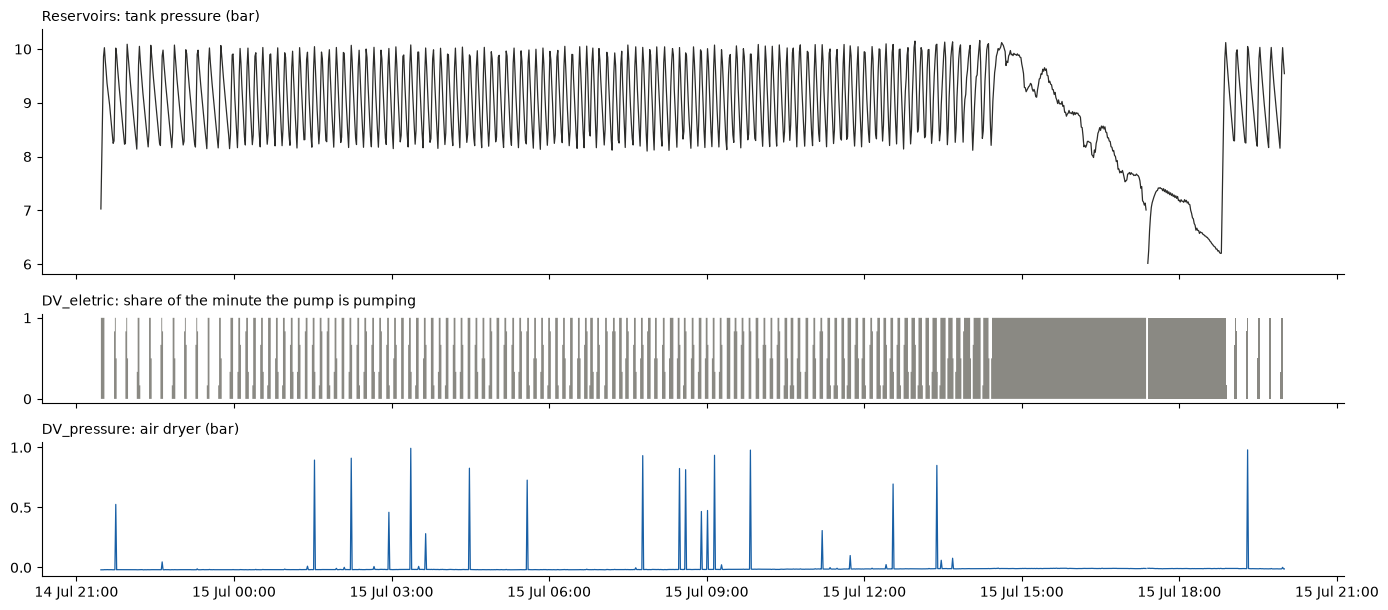

In [15]:
preview = df_readings[(df_readings["minute"] >= PREVIEW_FROM) & (df_readings["minute"] <= PREVIEW_UNTIL)].set_index("minute")
preview = preview.reindex(pd.date_range(PREVIEW_FROM, PREVIEW_UNTIL, freq=MINUTE))
fig, axes = plt.subplots(3, 1, figsize=(14, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 0.8, 1.2]})
for ax, signal, title, color in zip(axes, READING_SIGNALS, ["Reservoirs: tank pressure (bar)", "DV_eletric: share of the minute the pump is pumping",
                                                          "DV_pressure: air dryer (bar)"], ["#2C2C2A", "#8A8983", "#185FA5"]):
    if signal == "DV_eletric":
        ax.fill_between(preview.index, preview[signal], step="post", color=color, linewidth=0)
        ax.set_yticks([0, 1])
    else:
        ax.plot(preview.index, preview[signal], color=color, linewidth=0.9)
    ax.set_title(title, fontsize=10, loc="left")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
plt.tight_layout()
plt.show()

> **What we see:** after the gap, the tank pressure saws up and down faster and faster: the pump starts more and more often, the sign of the slow puncture before leak 4 (notebook 5.3). During the leak itself, the pump runs without a break, and still the tank pressure falls. These are exactly the lines the Replay page draws, minute by minute.

## Why the Forest Scored Each Window

### SHAP Values of the Test Windows

> As in notebook 5.3, SHAP splits the path length of every test window into 40 pushes, one per summary number. A positive push made the window easier to cut away, so it pushed the score up. The pushes are then gathered per signal, plus the group *pump cycles*, so the app can show which signals made a window look unusual. The check makes sure that the pushes give back every score of the forest.

In [16]:
explainer = shap.TreeExplainer(forest)
shap_values = forest_shap(explainer=explainer, features=df_test_windows[FEATURE_COLUMNS], chunk_size=SHAP_CHUNK, label="SHAP values, test windows")
start_path = float(np.ravel(explainer.expected_value)[0])
pushes = pd.DataFrame(-shap_values, columns=FEATURE_COLUMNS)
FEATURE_SIGNAL = {feature: "pump cycles" if feature in CYCLE_FEATURES else next(signal for signal in SIGNALS if feature.startswith(f"{signal}_")) for feature in FEATURE_COLUMNS}
df_parts = parts_per_signal(parts=pushes, signal_of=FEATURE_SIGNAL, signal_order=SIGNALS + ["pump cycles"])
c = average_path_length(n=forest.max_samples_)
paths = start_path - df_parts.sum(axis=1).to_numpy()

print(f"Starting point: {start_path:.3f} cuts | groups: {df_parts.shape[1]} ({len(SIGNALS)} signals and pump cycles)")
print(f"Largest difference between the score from SHAP and the score of the forest: {np.abs(2 ** (-paths / c) - df_test['isolation_forest'].to_numpy()).max():.1e}")
check("SHAP adds up: the pushes of every test window give back its score", np.allclose(2 ** (-paths / c), df_test["isolation_forest"].to_numpy(), rtol=0, atol=1e-9))

SHAP values, test windows: 100%|██████████| 17/17 [01:20<00:00,  4.74s/it]

Starting point: 12.508 cuts | groups: 13 (12 signals and pump cycles)
Largest difference between the score from SHAP and the score of the forest: 5.6e-16
PASS  SHAP adds up: the pushes of every test window give back its score


## Save

### What Will Be Written

> - `app/data/readings.parquet`: one row per minute with a reading: the minute, the tank pressure and the air dryer pressure in bar, and the share of the minute the pump was pumping.
> - `app/data/forest_parts.parquet`: one row per test window: its end, and the push of every signal group.
>
> Both are stored as 32-bit numbers (about 7 digits), which is more than a chart can show, and with zstd compression, so the files stay small for the repo and the online app.

In [17]:
df_readings[READING_SIGNALS] = df_readings[READING_SIGNALS].astype("float32")
df_parts = df_parts.astype("float32")
df_parts.insert(0, "end", df_test["end"].to_numpy())
for name, frame, path in [("readings", df_readings, READINGS_FILE), ("forest_parts", df_parts, PARTS_FILE)]:
    print(f"{name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns | {os.path.relpath(path, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(path) else 'new file'}")
    display(frame.head(3))

readings: 179,230 rows x 4 columns | app\data\readings.parquet: new file


,minute,Reservoirs,DV_eletric,DV_pressure
0,2020-03-31 23:00:00,9.847600,0.0,-0.023200
1,2020-03-31 23:01:00,9.747334,0.0,-0.024333
2,2020-03-31 23:02:00,9.641000,0.0,-0.023667


forest_parts: 33,507 rows x 14 columns | app\data\forest_parts.parquet: new file


,end,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,Pressure_switch,pump cycles
0,2020-04-01 00:00:00,0.440092,0.179536,0.562033,0.543762,0.119776,1.262621,0.312366,0.099968,0.056163,0.099828,0.061862,-0.097401,0.506335
1,2020-04-01 00:05:00,0.456800,0.142299,0.615216,0.554447,0.048922,1.284077,0.133601,0.078184,0.055232,0.097131,0.059492,-0.099517,0.482714
2,2020-04-01 00:10:00,0.847068,0.182952,0.799091,0.463573,0.154544,1.086587,0.379910,0.527540,0.386849,0.430165,0.535362,-0.058968,0.556035


### Save the Two Files

In [18]:
os.makedirs(APP_DATA_DIR, exist_ok=True)
df_readings.to_parquet(READINGS_FILE, index=False, compression="zstd")
df_parts.to_parquet(PARTS_FILE, index=False, compression="zstd")
for path in [READINGS_FILE, PARTS_FILE]:
    print(f"Saved {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1e6:,.1f} MB)")

Saved app\data\readings.parquet (1.7 MB)
Saved app\data\forest_parts.parquet (2.5 MB)


### Read the Files Back

In [19]:
readings_back = pd.read_parquet(READINGS_FILE)
parts_back = pd.read_parquet(PARTS_FILE)
check("both files read back the same",
      list(readings_back.columns) == list(df_readings.columns) and np.array_equal(readings_back["minute"].to_numpy(), df_readings["minute"].to_numpy())
      and np.array_equal(readings_back[READING_SIGNALS].to_numpy(), df_readings[READING_SIGNALS].to_numpy())
      and list(parts_back.columns) == list(df_parts.columns) and np.array_equal(parts_back["end"].to_numpy(), df_parts["end"].to_numpy())
      and np.array_equal(parts_back.drop(columns="end").to_numpy(), df_parts.drop(columns="end").to_numpy()))

PASS  both files read back the same


## Result

### Final Result

> If every check passed, the two files of the app are saved and match the grid, the forest and the saved scores. If a check failed, its name is printed.

In [20]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (7 checks)


## Summary

> - The app replays saved results and runs no model. Most of what it shows is already in `results/`; this notebook added the two missing files.
> - `app/data/readings.parquet`: what the compressor did in the test months, minute by minute, in real units: the tank pressure, the pump and the air dryer.
> - `app/data/forest_parts.parquet`: for every test window, the push of every signal group on the forest's score (SHAP, as in notebook 5.3). The pushes give back every score exactly.
>
> **Next: open the dashboard.** In the terminal of VS Code, in the project folder:
>
> ```
> .venv\Scripts\python.exe -m streamlit run app/app.py
> ```
>
> Then open the Local URL it prints (http://localhost:8501). Stop the app with Ctrl+C in the terminal.